In [39]:
import sys
sys.path.append('/home/shrgarg/hcd_priya/')

from shrgarg_script.DLA_priya_shrgarg import arg_max_DLA_finding


In [40]:
import h5py
from matplotlib import pyplot as plt
import numpy as np
from scipy.signal import find_peaks
from pathlib import Path
import json



Number of spectra: 3
Number of DLAs detected: 5
[
  {
    "S.No": 1,
    "spect_id": 1,
    "x_coord": 188,
    "y_coord": 6.2755818367004395
  },
  {
    "S.No": 2,
    "spect_id": 1,
    "x_coord": 198,
    "y_coord": 6.585180282592773
  },
  {
    "S.No": 3,
    "spect_id": 1,
    "x_coord": 204,
    "y_coord": 6.786784648895264
  },
  {
    "S.No": 4,
    "spect_id": 4,
    "x_coord": 296,
    "y_coord": 7.894219398498535
  },
  {
    "S.No": 5,
    "spect_id": 9,
    "x_coord": 1184,
    "y_coord": 6.377840995788574
  }
]
Retrieved 5 peaks from analysis


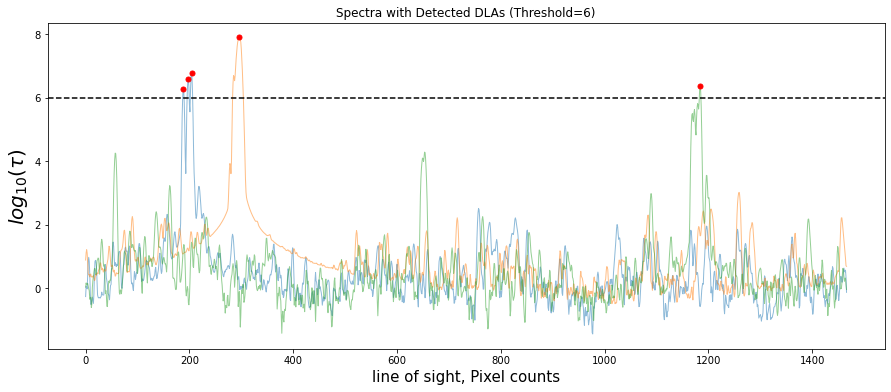

In [41]:
if __name__ == "__main__":
    file_path = 'ns0.859Ap1.29e-09herei3.92heref2.72alphaq1.87hub0.693omegamh20.141hireionz7.15bhfeedback0.0579/' 
    SNAP = 11
    path_append = 'output/' + f'SPECTRA_{SNAP:03d}' + '/lya_forest_spectra_grid_480.hdf5'
    file_path_add = Path('/scratch/cavestru_root/cavestru0/mfho/priya/emu_full/')
    file_path = file_path_add / file_path / path_append
    
    # Run analysis
    results = arg_max_DLA_finding(
        file_path=file_path,
        n_spectra=10,
        threshold=6,
        save_json=True
    )
    
    dla_data = results['dla_dict']
    peaks = results['all_peaks']
    print(f"Retrieved {len(peaks)} peaks from analysis")


In [42]:
# with file_path as f:
#     plt.plot(np.exp(-f['tau/H/1/1215'][4,:]), color='C'+str(4))

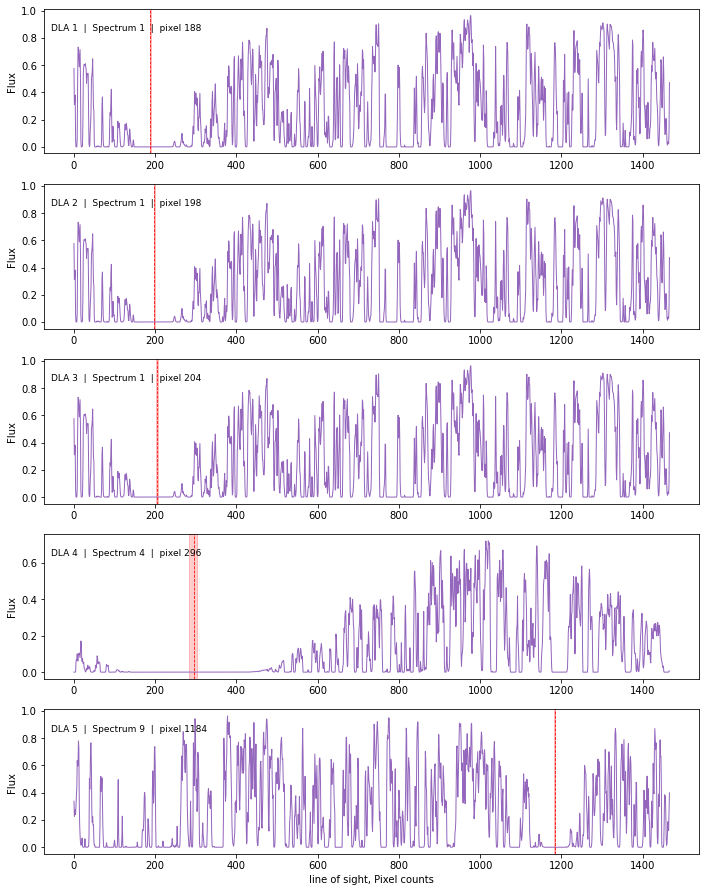

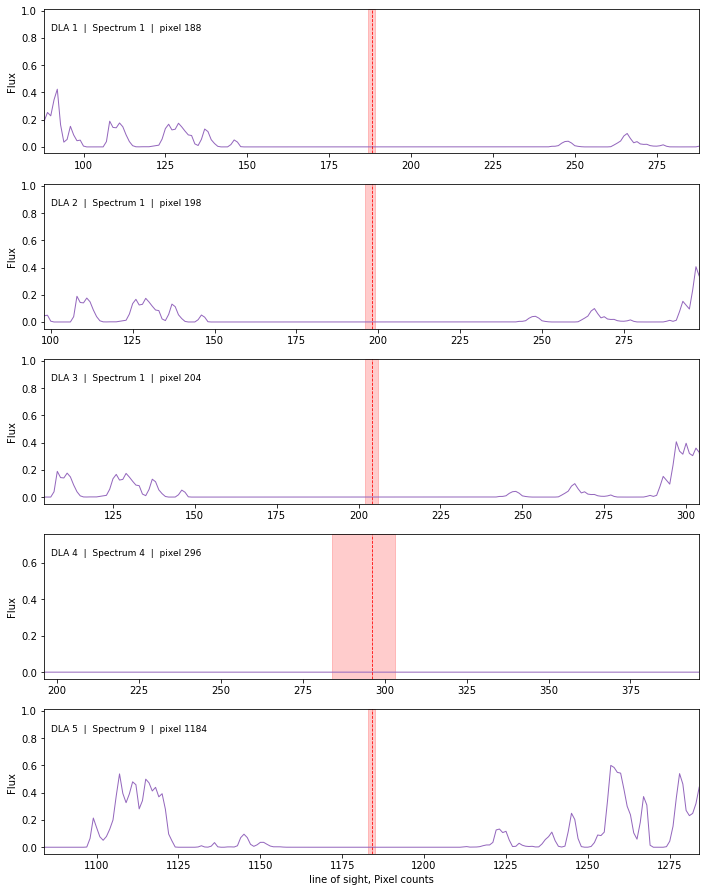

In [43]:
import h5py
import numpy as np
import matplotlib.pyplot as plt
from DLA_priya_shrgarg import regions_above_threshold


def plot_dla_flux_panels(file_path, dla_dict, threshold=6, window=None,
                         save_path="DLA_flux_panels.pdf"):
    """One panel per DLA: flux = exp(-tau) of its spectrum, that DLA's region shaded
    and its peak marked. window: optional half-width (pixels) to zoom around the DLA."""
    if not dla_dict:
        print("No DLAs found.")
        return None, None

    spec_ids = sorted({d['spect_id'] for d in dla_dict})
    with h5py.File(file_path, 'r') as f:
        tau = dict(zip(spec_ids, f['tau/H/1/1215'][spec_ids, :]))  # h5py needs sorted indices

    fig, axes = plt.subplots(len(dla_dict), 1, figsize=(10, 2.5 * len(dla_dict)),
                             squeeze=False)
    for ax, d in zip(axes[:, 0], dla_dict):
        t, x = tau[d['spect_id']], d['x_coord']
        ax.plot(np.exp(-t), color='tab:purple', lw=1)
        for start, end in regions_above_threshold(np.log10(t), threshold):
            if start <= x <= end:                       # shade only this DLA's region
                ax.axvspan(start, end, color='red', alpha=0.2)
        ax.axvline(x, color='red', ls='--', lw=0.8)
        if window:
            ax.set_xlim(max(x - window, 0), min(x + window, len(t) - 1))
        ax.set_ylabel('Flux')
        ax.text(0.01, 0.85, f"DLA {d['S.No']}  |  Spectrum {d['spect_id']}  |  pixel {x}",
                transform=ax.transAxes, fontsize=9)

    axes[-1, 0].set_xlabel('line of sight, Pixel counts')
    fig.tight_layout()
    # if save_path:
    #     fig.savefig(save_path)
    # plt.show()
    # return fig, axes


# Usage, after running arg_max_DLA_finding:
plot_dla_flux_panels(file_path, results['dla_dict'], threshold=6)
plot_dla_flux_panels(file_path, results['dla_dict'], window=100)  # zoom ±100 px